<a href="https://colab.research.google.com/github/wardinamajid2002/carbon-footprint/blob/main/carbon_footprint.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install codecarbon transformers torch matplotlib

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


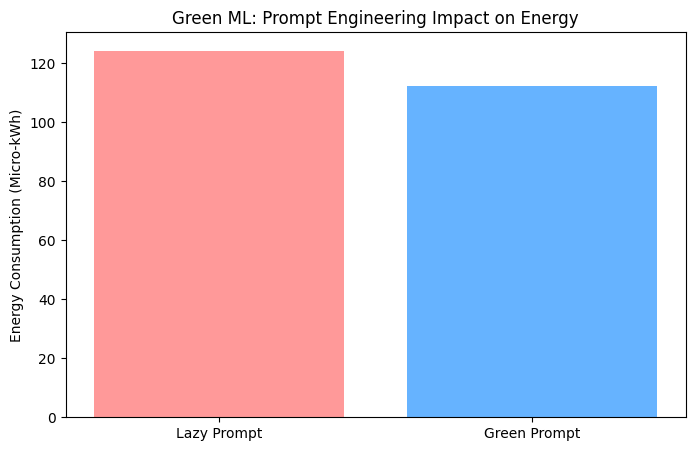

Lazy Prompt Tokens: 114 | Green Prompt Tokens: 118


In [ ]:
import matplotlib.pyplot as plt
from codecarbon import EmissionsTracker
from transformers import pipeline

# Load a small, energy-efficient model
pipe = pipeline("text-generation", model="microsoft/Phi-3-mini-4k-instruct", device=0)

def run_test(prompt, label):
    tracker = EmissionsTracker(save_to_file=False, log_level="error")
    tracker.start()

    # ML Inference happens here
    result = pipe(prompt, max_new_tokens=150, clean_up_tokenization_spaces=True)

    emissions = tracker.stop() # Returns kWh
    token_count = len(result[0]['generated_text'].split())
    return emissions, token_count

# Run the experiments
lazy_energy, lazy_tokens = run_test("can i drink coffee and matcha in the same time", "Lazy")
green_energy, green_tokens = run_test("As a nutritionist, can you outline the pros and cons if i drink coffee and matcha at the same time", "Green")

# --- Visualization ---
labels = ['Lazy Prompt', 'Green Prompt']
energy_values = [lazy_energy * 1000000, green_energy * 1000000] # Convert to Micro-kWh for visibility

plt.figure(figsize=(8, 5))
colors = ['#ff9999','#66b3ff']
plt.bar(labels, energy_values, color=colors)
plt.ylabel('Energy Consumption (Micro-kWh)')
plt.title('Green ML: Prompt Engineering Impact on Energy')
plt.show()

print(f"Lazy Prompt Tokens: {lazy_tokens} | Green Prompt Tokens: {green_tokens}")

In [ ]:
import torch
import time
from transformers import pipeline

# 1. Initialize the model on the GPU (device=0)
pipe = pipeline("text-generation", model="microsoft/Phi-3-mini-4k-instruct", device=0)

def measure_gpu_runtime(prompt):
    # Create CUDA events to track start and end
    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)

    # Start the clock
    start_event.record()

    # Run the AI
    output = pipe(prompt, max_new_tokens=100, do_sample=True)

    # Stop the clock
    end_event.record()

    # Wait for the GPU to finish (Synchronization)
    torch.cuda.synchronize()

    # Calculate time in milliseconds
    elapsed_time = start_event.elapsed_time(end_event)
    return elapsed_time, output[0]['generated_text']

# --- The Comparison ---
lazy_time, _ = measure_gpu_runtime("Write a long story about coding.")
green_time, _ = measure_gpu_runtime("Summarize coding in 1 word.")

print(f"Lazy Prompt GPU Time: {lazy_time:.2f} ms")
print(f"Green Prompt GPU Time: {green_time:.2f} ms")
print(f"Efficiency Gain: {((lazy_time - green_time) / lazy_time) * 100:.1f}%")

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Lazy Prompt GPU Time: 6056.22 ms
Green Prompt GPU Time: 4752.43 ms
Efficiency Gain: 21.5%
